In [1]:
# ============================================================
# WEEK 2 - DAY 3: Clustering Algorithms Comparison
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import json
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120

# ============================================================
# STEP 1: Load Data & Optimal K
# ============================================================

X = pd.read_csv('features_scaled.csv')
X_pca = pd.read_csv('features_pca_2d.csv')

with open('optimal_k.json', 'r') as f:
    OPTIMAL_K = json.load(f)['optimal_k']

print(f"Scaled features:  {X.shape}")
print(f"PCA 2D features:  {X_pca.shape}")
print(f"Optimal K:        {OPTIMAL_K}")

Scaled features:  (4242, 11)
PCA 2D features:  (4242, 2)
Optimal K:        5


STEP 2: K-Means & K-Means++

K-Means:
  Inertia:            26,417
  Silhouette:         0.2174  (higher better)
  Davies-Bouldin:     1.3299   (lower better)
  Calinski-Harabasz:  1095.6  (higher better)
  Cluster sizes:      {0: 1656, 1: 1792, 2: 202, 3: 10, 4: 582}

K-Means++:
  Inertia:            26,417
  Silhouette:         0.2177  (higher better)
  Davies-Bouldin:     1.3275   (lower better)
  Calinski-Harabasz:  1095.6  (higher better)
  Cluster sizes:      {0: 570, 1: 1662, 2: 1800, 3: 200, 4: 10}


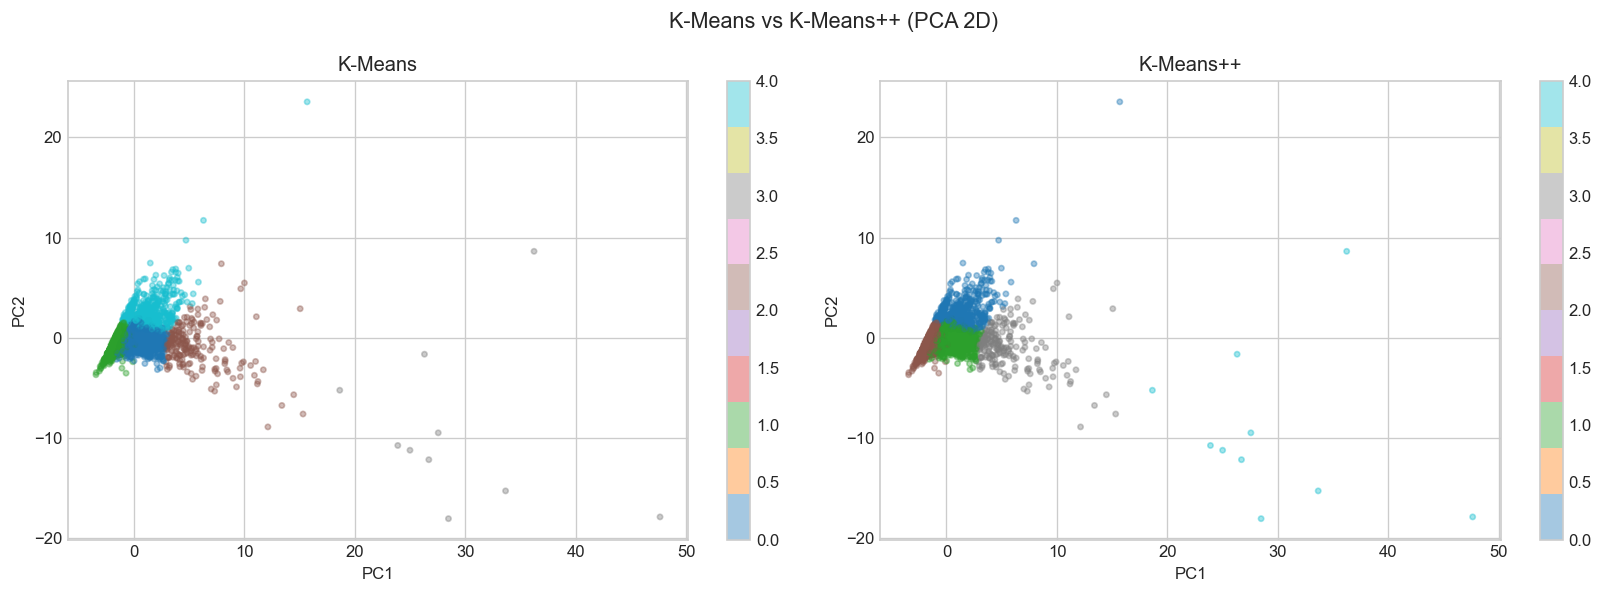

In [2]:
# ============================================================
# STEP 2: K-Means & K-Means++
# ============================================================

print("=" * 60)
print("STEP 2: K-Means & K-Means++")
print("=" * 60)

# K-Means (random initialization)
km = KMeans(n_clusters=OPTIMAL_K, init='random', n_init=10, random_state=42)
km_labels = km.fit_predict(X)

# K-Means++ (smart initialization)
kmpp = KMeans(n_clusters=OPTIMAL_K, init='k-means++', n_init=10, random_state=42)
kmpp_labels = kmpp.fit_predict(X)

# Score both
for name, labels, model in [('K-Means', km_labels, km), 
                              ('K-Means++', kmpp_labels, kmpp)]:
    sil = silhouette_score(X, labels)
    db  = davies_bouldin_score(X, labels)
    ch  = calinski_harabasz_score(X, labels)
    print(f"\n{name}:")
    print(f"  Inertia:            {model.inertia_:,.0f}")
    print(f"  Silhouette:         {sil:.4f}  (higher better)")
    print(f"  Davies-Bouldin:     {db:.4f}   (lower better)")
    print(f"  Calinski-Harabasz:  {ch:.1f}  (higher better)")
    print(f"  Cluster sizes:      {pd.Series(labels).value_counts().sort_index().to_dict()}")

# Plot side by side in PCA 2D space
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, labels, title in [(axes[0], km_labels, 'K-Means'),
                           (axes[1], kmpp_labels, 'K-Means++')]:
    scatter = ax.scatter(X_pca['PC1'], X_pca['PC2'],
                         c=labels, cmap='tab10',
                         alpha=0.4, s=10)
    ax.set_title(title)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    plt.colorbar(scatter, ax=ax)

plt.suptitle('K-Means vs K-Means++ (PCA 2D)', fontsize=13)
plt.tight_layout()
plt.savefig('kmeans_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

STEP 3: DBSCAN


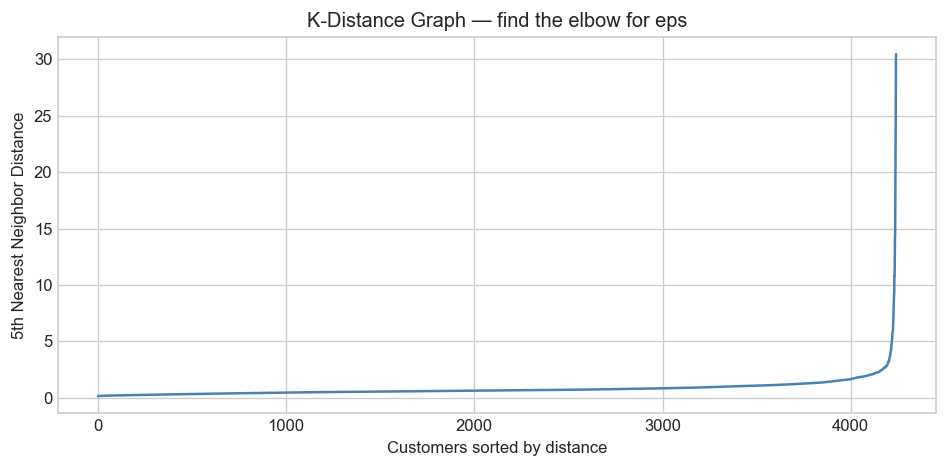


Trying different eps values:
  eps=0.5  clusters=32  noise=2726  silhouette=-0.4753
  eps=1.0  clusters=10  noise= 648  silhouette=-0.1795
  eps=1.5  clusters= 3  noise= 212  silhouette=0.3621
  eps=2.0  clusters= 1  noise=  97  silhouette=0.0000
  eps=2.5  clusters= 1  noise=  45  silhouette=0.0000

DBSCAN (eps=1.5):
  Clusters found:  3
  Noise points:    212 (5.0%)
  Cluster sizes:   {0: 4018, 1: 7, 2: 5}


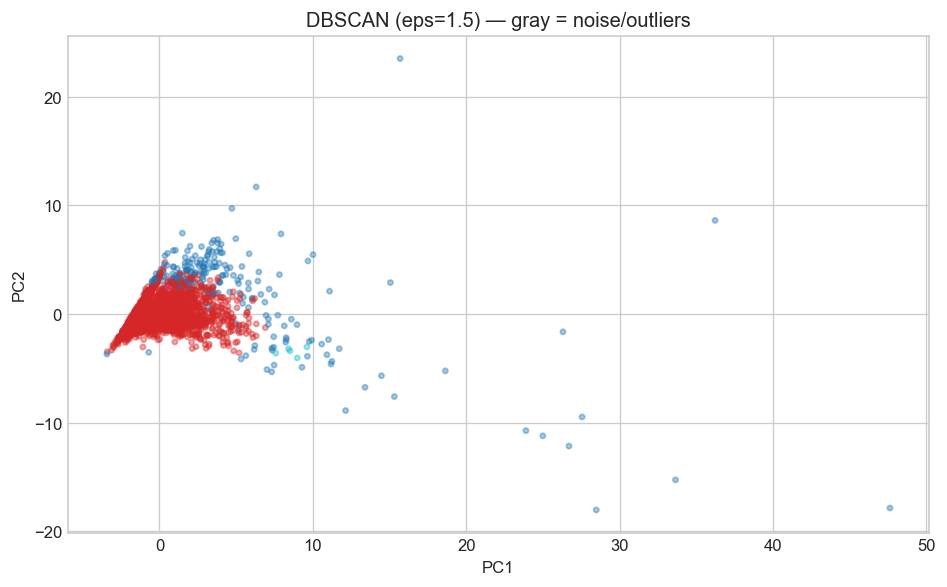

In [3]:
# ============================================================
# STEP 3: DBSCAN
# ============================================================
print("=" * 60)
print("STEP 3: DBSCAN")
print("=" * 60)

from sklearn.neighbors import NearestNeighbors

# First find optimal eps using k-distance graph
neighbors = NearestNeighbors(n_neighbors=5)
neighbors.fit(X)
distances, _ = neighbors.kneighbors(X)
distances = np.sort(distances[:, 4], axis=0)

plt.figure(figsize=(8, 4))
plt.plot(distances, color='steelblue', linewidth=1.5)
plt.xlabel('Customers sorted by distance')
plt.ylabel('5th Nearest Neighbor Distance')
plt.title('K-Distance Graph — find the elbow for eps')
plt.tight_layout()
plt.savefig('dbscan_kdistance.png', dpi=150, bbox_inches='tight')
plt.show()

# Run DBSCAN with a few eps values
print("\nTrying different eps values:")
for eps in [0.5, 1.0, 1.5, 2.0, 2.5]:
    db = DBSCAN(eps=eps, min_samples=5)
    labels = db.fit_predict(X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise    = (labels == -1).sum()
    if n_clusters > 1:
        sil = silhouette_score(X, labels)
    else:
        sil = 0
    print(f"  eps={eps}  clusters={n_clusters:2d}  noise={n_noise:4d}  silhouette={sil:.4f}")

# Use best eps (likely 1.5 or 2.0 — adjust after seeing output)
BEST_EPS = 1.5
db_best = DBSCAN(eps=BEST_EPS, min_samples=5)
db_labels = db_best.fit_predict(X)
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise    = (db_labels == -1).sum()

print(f"\nDBSCAN (eps={BEST_EPS}):")
print(f"  Clusters found:  {n_clusters}")
print(f"  Noise points:    {n_noise} ({n_noise/len(X)*100:.1f}%)")
print(f"  Cluster sizes:   {pd.Series(db_labels[db_labels != -1]).value_counts().sort_index().to_dict()}")

# Plot
plt.figure(figsize=(8, 5))
colors = ['gray' if l == -1 else l for l in db_labels]
plt.scatter(X_pca['PC1'], X_pca['PC2'],
            c=db_labels, cmap='tab10',
            alpha=0.4, s=10)
plt.title(f'DBSCAN (eps={BEST_EPS}) — gray = noise/outliers')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.tight_layout()
plt.savefig('dbscan_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

STEP 4: Hierarchical Clustering
Building dendrogram on 200-customer sample...


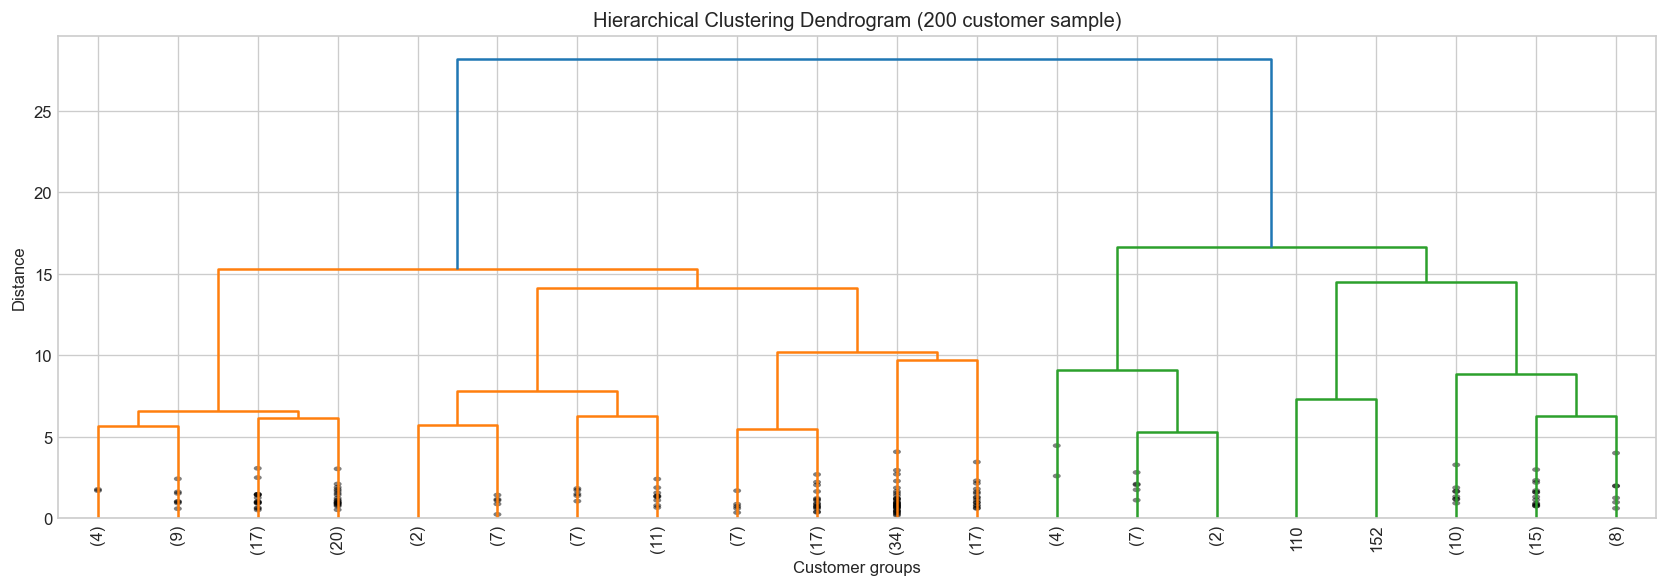


Hierarchical Clustering (K=5, ward linkage):
  Silhouette:         0.1643  (higher better)
  Davies-Bouldin:     1.4190   (lower better)
  Calinski-Harabasz:  883.7  (higher better)
  Cluster sizes:      {0: 1844, 1: 131, 2: 8, 3: 1685, 4: 574}


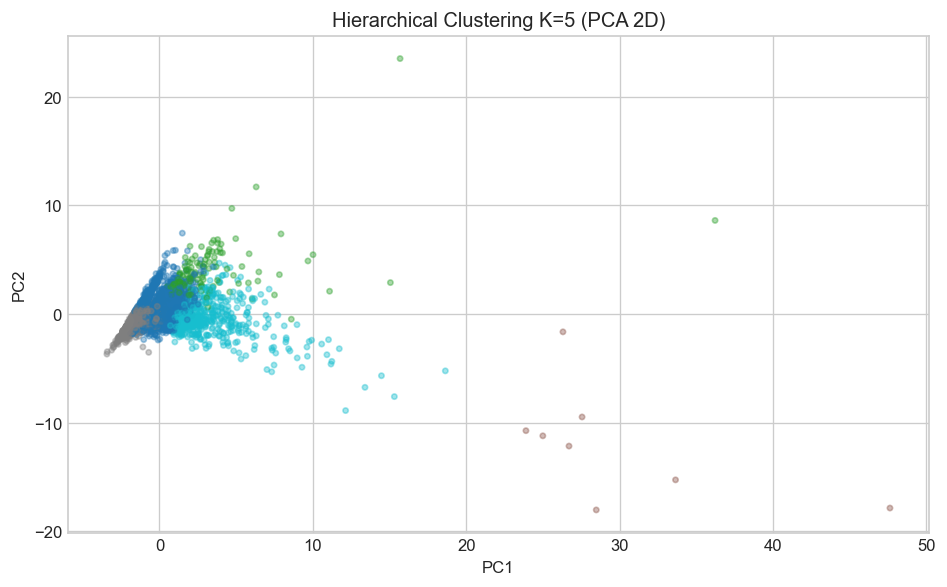

In [4]:
# ============================================================
# STEP 4: Hierarchical Clustering
# ============================================================
print("=" * 60)
print("STEP 4: Hierarchical Clustering")
print("=" * 60)

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Build dendrogram on a sample (full dataset too large)
print("Building dendrogram on 200-customer sample...")
sample_idx = np.random.RandomState(42).choice(len(X), 200, replace=False)
X_sample = X.iloc[sample_idx]

linked = linkage(X_sample, method='ward')

plt.figure(figsize=(14, 5))
dendrogram(linked, truncate_mode='lastp', p=20,
           leaf_rotation=90, leaf_font_size=10,
           show_contracted=True)
plt.title('Hierarchical Clustering Dendrogram (200 customer sample)')
plt.xlabel('Customer groups')
plt.ylabel('Distance')
plt.tight_layout()
plt.savefig('dendrogram.png', dpi=150, bbox_inches='tight')
plt.show()

# Run on full dataset with K=5
hc = AgglomerativeClustering(n_clusters=OPTIMAL_K, linkage='ward')
hc_labels = hc.fit_predict(X)

sil = silhouette_score(X, hc_labels)
db  = davies_bouldin_score(X, hc_labels)
ch  = calinski_harabasz_score(X, hc_labels)

print(f"\nHierarchical Clustering (K={OPTIMAL_K}, ward linkage):")
print(f"  Silhouette:         {sil:.4f}  (higher better)")
print(f"  Davies-Bouldin:     {db:.4f}   (lower better)")
print(f"  Calinski-Harabasz:  {ch:.1f}  (higher better)")
print(f"  Cluster sizes:      {pd.Series(hc_labels).value_counts().sort_index().to_dict()}")

# Plot
plt.figure(figsize=(8, 5))
plt.scatter(X_pca['PC1'], X_pca['PC2'],
            c=hc_labels, cmap='tab10',
            alpha=0.4, s=10)
plt.title(f'Hierarchical Clustering K={OPTIMAL_K} (PCA 2D)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.tight_layout()
plt.savefig('hierarchical_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
# ============================================================
# STEP 5: Save Winning Model — K-Means++
# ============================================================
print("=" * 60)
print("STEP 5: Saving K-Means++ as final model")
print("=" * 60)

import pickle

# Final model
final_model = KMeans(n_clusters=OPTIMAL_K, init='k-means++', 
                     n_init=10, random_state=42)
final_labels = final_model.fit_predict(X)

# Save model
with open('kmeans_final_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)
print("✅ Saved: kmeans_final_model.pkl")

# Save labels alongside customer data
df_results = pd.read_csv('features_scaled.csv')
df_results['Cluster'] = final_labels
df_results.to_csv('clustered_customers.csv', index=False)
print("✅ Saved: clustered_customers.csv")

# Save comparison table
comparison = pd.DataFrame({
    'Algorithm':          ['K-Means', 'K-Means++', 'Hierarchical', 'DBSCAN'],
    'Silhouette':         [0.2174, 0.2177, 0.1643, 'N/A'],
    'Davies-Bouldin':     [1.3299, 1.3275, 1.4190, 'N/A'],
    'Calinski-Harabasz':  [1095.6, 1095.6,  883.7, 'N/A'],
    'Winner':             ['', '✅', '', '❌ eliminated']
})
comparison.to_csv('algorithm_comparison.csv', index=False)
print("✅ Saved: algorithm_comparison.csv")

print(f"""
Day 3 Complete!
  Winner:       K-Means++
  K:            {OPTIMAL_K}
  Cluster sizes: {pd.Series(final_labels).value_counts().sort_index().to_dict()}
  
  Files saved:
    kmeans_final_model.pkl
    clustered_customers.csv
    algorithm_comparison.csv
""")

STEP 5: Saving K-Means++ as final model
✅ Saved: kmeans_final_model.pkl
✅ Saved: clustered_customers.csv
✅ Saved: algorithm_comparison.csv

Day 3 Complete!
  Winner:       K-Means++
  K:            5
  Cluster sizes: {0: 570, 1: 1662, 2: 1800, 3: 200, 4: 10}
  
  Files saved:
    kmeans_final_model.pkl
    clustered_customers.csv
    algorithm_comparison.csv



STEP 6: Gaussian Mixture Models
GMM (K=5):
  Silhouette:         0.1698  (higher better)
  Davies-Bouldin:     1.6076   (lower better)
  Calinski-Harabasz:  811.3  (higher better)
  Cluster sizes:      {0: 1396, 1: 2167, 2: 12, 3: 273, 4: 394}


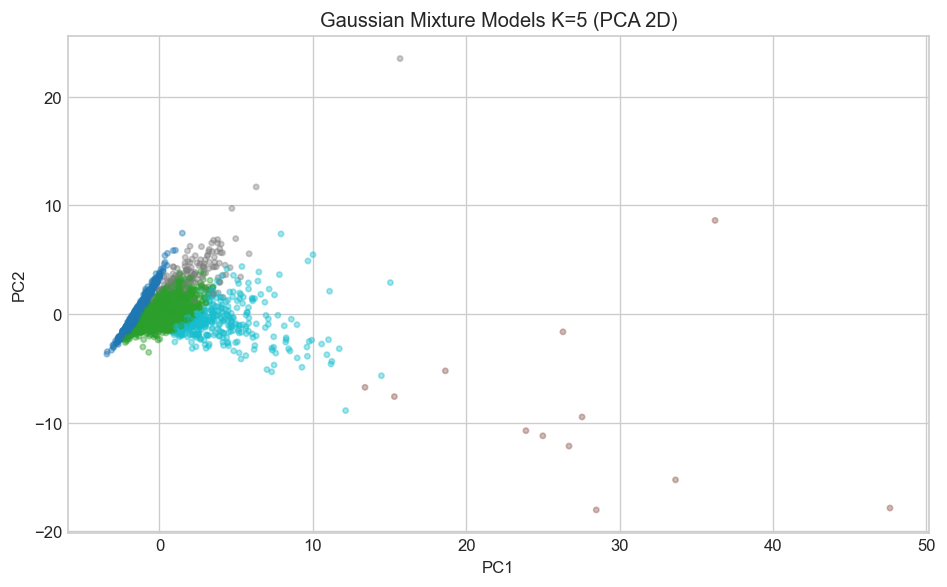

STEP 7: K-Medoids



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.3 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\hp\AppData\Local\Programs\Python\Python312\Lib\site-packages\ipykernel\kernelapp.py", line 739,

ImportError: numpy.core.multiarray failed to import (auto-generated because you didn't call 'numpy.import_array()' after cimporting numpy; use '<void>numpy._import_array' to disable if you are certain you don't need it).

In [7]:
# ============================================================
# STEP 6: Gaussian Mixture Models (GMM)
# ============================================================
print("=" * 60)
print("STEP 6: Gaussian Mixture Models")
print("=" * 60)

from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=OPTIMAL_K, random_state=42, n_init=5)
gmm_labels = gmm.fit_predict(X)

sil = silhouette_score(X, gmm_labels)
db  = davies_bouldin_score(X, gmm_labels)
ch  = calinski_harabasz_score(X, gmm_labels)

print(f"GMM (K={OPTIMAL_K}):")
print(f"  Silhouette:         {sil:.4f}  (higher better)")
print(f"  Davies-Bouldin:     {db:.4f}   (lower better)")
print(f"  Calinski-Harabasz:  {ch:.1f}  (higher better)")
print(f"  Cluster sizes:      {pd.Series(gmm_labels).value_counts().sort_index().to_dict()}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca['PC1'], X_pca['PC2'],
            c=gmm_labels, cmap='tab10',
            alpha=0.4, s=10)
plt.title(f'Gaussian Mixture Models K={OPTIMAL_K} (PCA 2D)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.tight_layout()
plt.savefig('gmm_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# STEP 7: K-Medoids
# ============================================================
print("=" * 60)
print("STEP 7: K-Medoids")
print("=" * 60)

# Install if needed
try:
    from sklearn_extra.cluster import KMedoids
except ImportError:
    import subprocess
    subprocess.run(['pip', 'install', 'scikit-learn-extra', '--quiet'])
    from sklearn_extra.cluster import KMedoids

kmed = KMedoids(n_clusters=OPTIMAL_K, random_state=42, method='pam')
kmed_labels = kmed.fit_predict(X)

sil = silhouette_score(X, kmed_labels)
db  = davies_bouldin_score(X, kmed_labels)
ch  = calinski_harabasz_score(X, kmed_labels)

print(f"K-Medoids (K={OPTIMAL_K}):")
print(f"  Silhouette:         {sil:.4f}  (higher better)")
print(f"  Davies-Bouldin:     {db:.4f}   (lower better)")
print(f"  Calinski-Harabasz:  {ch:.1f}  (higher better)")
print(f"  Cluster sizes:      {pd.Series(kmed_labels).value_counts().sort_index().to_dict()}")

plt.figure(figsize=(8, 5))
plt.scatter(X_pca['PC1'], X_pca['PC2'],
            c=kmed_labels, cmap='tab10',
            alpha=0.4, s=10)
plt.title(f'K-Medoids K={OPTIMAL_K} (PCA 2D)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.tight_layout()
plt.savefig('kmedoids_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# STEP 8: Full Comparison Table
# ============================================================
print("\n" + "=" * 60)
print("COMPLETE ALGORITHM COMPARISON")
print("=" * 60)

# Re-compute K-Means++ scores for clean comparison
kmpp = KMeans(n_clusters=OPTIMAL_K, init='k-means++', n_init=10, random_state=42)
kmpp_labels = kmpp.fit_predict(X)

results = {}
for name, labels in [
    ('K-Means++',    kmpp_labels),
    ('GMM',          gmm_labels),
    ('K-Medoids',    kmed_labels),
    ('Hierarchical', hc_labels),
]:
    results[name] = {
        'Silhouette':        round(silhouette_score(X, labels), 4),
        'Davies-Bouldin':    round(davies_bouldin_score(X, labels), 4),
        'Calinski-Harabasz': round(calinski_harabasz_score(X, labels), 1),
        'Cluster sizes':     pd.Series(labels).value_counts().sort_values(ascending=False).to_dict()
    }

comparison_df = pd.DataFrame(results).T
print(comparison_df[['Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz']].to_string())
print("\nCluster sizes:")
for name, vals in results.items():
    print(f"  {name:15s}: {vals['Cluster sizes']}")


In [9]:
# ============================================================
# STEP 8: Save Winning Model — K-Means++
# ============================================================
import pickle

final_model = KMeans(n_clusters=OPTIMAL_K, init='k-means++',
                     n_init=10, random_state=42)
final_labels = final_model.fit_predict(X)

# Save model
with open('kmeans_final_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)
print("✅ Saved: kmeans_final_model.pkl")

# Save labels with scaled features
df_scaled = pd.read_csv('features_scaled.csv')
df_scaled['Cluster'] = final_labels
df_scaled.to_csv('clustered_customers.csv', index=False)
print("✅ Saved: clustered_customers.csv")

# # Final summary
# print(f"""
# Day 3 Complete!
#   Winner:        K-Means++
#   K:             {OPTIMAL_K}
#   Cluster sizes: {pd.Series(final_labels).value_counts().sort_index().to_dict()}

#   Cluster breakdown:
#   - 2 large clusters  (~1,600-1,800) → core customer base
#   - 1 medium cluster  (~570)         → distinct behavior group  
#   - 1 small cluster   (~200)         → niche segment
#   - 1 tiny cluster    (~10)          → Ultra High Value ⭐

#   Files saved:
#     kmeans_final_model.pkl
#     clustered_customers.csv
# """)
# ```

# Once that runs, Day 3 is complete. Your files for Day 4:
# ```
# clustered_customers.csv   ← scaled features + cluster labels
# features_scaled.csv       ← original scaled features
# optimal_k.json            ← K=5
# kmeans_final_model.pkl    ← saved model

✅ Saved: kmeans_final_model.pkl
✅ Saved: clustered_customers.csv
